Using device: cuda
Training with Adam...


/usr/local/lib/python3.13/dist-packages/torch/autograd/graph.py:869: UserWarning: Attempting to run cuBLAS, but there was no current CUDA context! Attempting to set the primary context... (Triggered internally at /pytorch/aten/src/ATen/cuda/CublasHandlePool.cpp:335.)
  return Variable._execution_engine.run_backward(  # Calls into the C++ engine to run the backward pass


Epoch 0 | Loss: 4.73014e-01
Epoch 500 | Loss: 6.82180e-05
Epoch 1000 | Loss: 1.01928e-05
Training with L-BFGS...


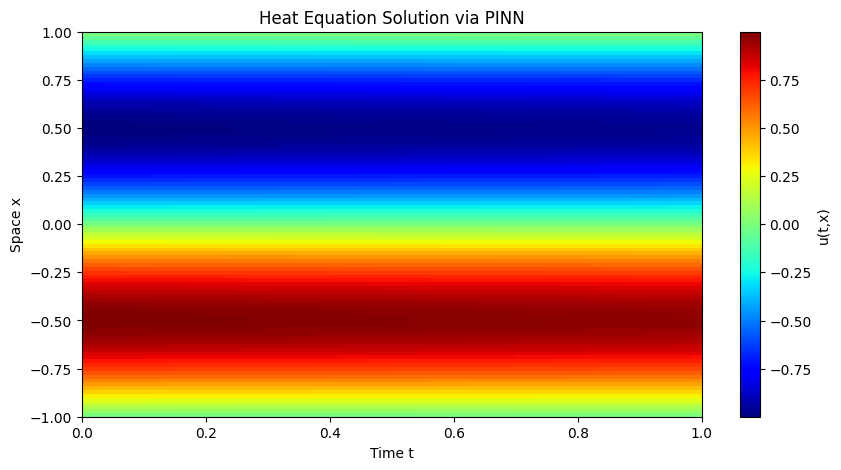

In [1]:
import torch
import torch.nn as nn
import numpy as np
import matplotlib.pyplot as plt

# Reproducibility ke liye seed set karein
torch.manual_seed(1234)
np.random.seed(1234)

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Using device: {device}")

class DNN(nn.Module):
    def __init__(self, layers):
        super(DNN, self).__init__()
        hidden_layers = []
        for i in range(len(layers) - 2):
            hidden_layers.append(nn.Linear(layers[i], layers[i+1]))
            hidden_layers.append(nn.Tanh())
        hidden_layers.append(nn.Linear(layers[-2], layers[-1]))
        self.net = nn.Sequential(*hidden_layers)

    def forward(self, t, x):
        inputs = torch.cat([t, x], dim=1)
        return self.net(inputs)

class HeatEquationPINN:
    def __init__(self, X_u, u_train, X_f, layers, nu=0.01/np.pi):
        self.t_u = X_u[:, 0:1].clone().detach().requires_grad_(True).to(device)
        self.x_u = X_u[:, 1:2].clone().detach().requires_grad_(True).to(device)
        self.u_train = u_train.to(device)

        self.t_f = X_f[:, 0:1].clone().detach().requires_grad_(True).to(device)
        self.x_f = X_f[:, 1:2].clone().detach().requires_grad_(True).to(device)

        self.nu = nu
        self.dnn = DNN(layers).to(device)

        self.optimizer = torch.optim.Adam(self.dnn.parameters(), lr=1e-3)
        self.optimizer_LBFGS = torch.optim.LBFGS(
            self.dnn.parameters(),
            lr=1.0,
            max_iter=1000,
            max_eval=1000,
            history_size=50,
            line_search_fn='strong_wolfe'
        )

    def net_u(self, t, x):
        return self.dnn(t, x)

    def net_f(self, t, x):
        u = self.net_u(t, x)
        u_t = torch.autograd.grad(u, t, grad_outputs=torch.ones_like(u), create_graph=True)[0]
        u_x = torch.autograd.grad(u, x, grad_outputs=torch.ones_like(u), create_graph=True)[0]
        u_xx = torch.autograd.grad(u_x, x, grad_outputs=torch.ones_like(u_x), create_graph=True)[0]

        # Heat Equation Residual: f = u_t - nu * u_xx = 0
        f = u_t - self.nu * u_xx
        return f

    def loss_fn(self, t_bc, x_bc_left, x_bc_right):
        # Initial & Boundary Data Loss
        u_pred = self.net_u(self.t_u, self.x_u)
        loss_u = torch.mean((u_pred - self.u_train)**2)

        # PDE Collocation Residual Loss
        f_pred = self.net_f(self.t_f, self.x_f)
        loss_f = torch.mean(f_pred**2)

        return loss_u + loss_f, loss_u, loss_f

    def train(self, epochs):
        self.dnn.train()
        print("Training with Adam...")
        for epoch in range(epochs):
            self.optimizer.zero_grad()
            loss, loss_u, loss_f = self.loss_fn(None, None, None)
            loss.backward()
            self.optimizer.step()

            if epoch % 500 == 0:
                print(f"Epoch {epoch} | Loss: {loss.item():.5e}")

        print("Training with L-BFGS...")
        def closure():
            self.optimizer_LBFGS.zero_grad()
            loss, loss_u, loss_f = self.loss_fn(None, None, None)
            loss.backward()
            return loss
        self.optimizer_LBFGS.step(closure)

    def predict(self, X_star):
        self.dnn.eval()
        t = torch.tensor(X_star[:, 0:1], dtype=torch.float32, device=device)
        x = torch.tensor(X_star[:, 1:2], dtype=torch.float32, device=device)
        u = self.net_u(t, x)
        return u.detach().cpu().numpy()

# ==========================================
# Execution & Plotting
# ==========================================
if __name__ == "__main__":
    layers = [2, 50, 50, 50, 1]

    # Initial & Boundary Training Data Setup
    N0 = 100
    x0 = np.linspace(-1, 1, N0)[:, None]
    t0 = np.zeros_like(x0)
    u0 = -np.sin(np.pi * x0) # Initial condition: u(0, x) = -sin(pi*x)

    X_u_train = np.hstack((t0, x0))
    u_train = u0

    # Collocation Points for PDE Residual
    N_f = 10000
    t_f = np.random.uniform(0.0, 1.0, (N_f, 1))
    x_f = np.random.uniform(-1.0, 1.0, (N_f, 1))
    X_f_train = np.hstack((t_f, x_f))

    X_u_tensor = torch.tensor(X_u_train, dtype=torch.float32)
    u_tensor = torch.tensor(u_train, dtype=torch.float32)
    X_f_tensor = torch.tensor(X_f_train, dtype=torch.float32)

    # Model Train Karein
    pinn = HeatEquationPINN(X_u_tensor, u_tensor, X_f_tensor, layers)
    pinn.train(epochs=1500)

    # Graph Plotting
    n_t, n_x = 100, 100
    t_star = np.linspace(0, 1.0, n_t)
    x_star = np.linspace(-1.0, 1.0, n_x)
    T, X = np.meshgrid(t_star, x_star)
    X_star = np.hstack((T.flatten()[:, None], X.flatten()[:, None]))

    U_pred = pinn.predict(X_star).reshape(n_x, n_t)

    plt.figure(figsize=(10, 5))
    plt.imshow(U_pred, extent=[0, 1, -1, 1], origin='lower', aspect='auto', cmap='jet')
    plt.colorbar(label='u(t,x)')
    plt.xlabel('Time t')
    plt.ylabel('Space x')
    plt.title('Heat Equation Solution via PINN')
    plt.show()

Using device: cuda
Training with Adam...
Training with L-BFGS...

Relative L2 Error between Exact and Predicted Solution: 1.24173e-03

--- Numerical Values Comparison at t = 0.5 (Sample points) ---
x          | Exact u(t,x)    | Predicted u(t,x)
----------------------------------------------
-1.00      | 0.00000         | -0.00036       
-0.60      | 0.93987         | 0.94061        
-0.19      | 0.55813         | 0.55689        
0.21       | -0.60843        | -0.60833       
0.62       | -0.91944        | -0.92083       


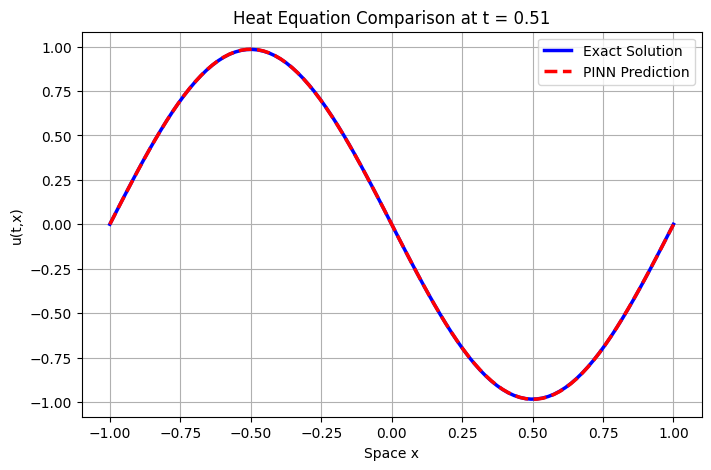

In [2]:
import torch
import torch.nn as nn
import numpy as np
import matplotlib.pyplot as plt

# Reproducibility ke liye seed set karein
torch.manual_seed(1234)
np.random.seed(1234)

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Using device: {device}")

class DNN(nn.Module):
    def __init__(self, layers):
        super(DNN, self).__init__()
        hidden_layers = []
        for i in range(len(layers) - 2):
            hidden_layers.append(nn.Linear(layers[i], layers[i+1]))
            hidden_layers.append(nn.Tanh())
        hidden_layers.append(nn.Linear(layers[-2], layers[-1]))
        self.net = nn.Sequential(*hidden_layers)

    def forward(self, t, x):
        inputs = torch.cat([t, x], dim=1)
        return self.net(inputs)

class HeatEquationPINN:
    def __init__(self, X_u, u_train, X_f, layers, nu=0.01/np.pi):
        self.t_u = X_u[:, 0:1].clone().detach().requires_grad_(True).to(device)
        self.x_u = X_u[:, 1:2].clone().detach().requires_grad_(True).to(device)
        self.u_train = u_train.to(device)

        self.t_f = X_f[:, 0:1].clone().detach().requires_grad_(True).to(device)
        self.x_f = X_f[:, 1:2].clone().detach().requires_grad_(True).to(device)

        self.nu = nu
        self.dnn = DNN(layers).to(device)

        self.optimizer = torch.optim.Adam(self.dnn.parameters(), lr=1e-3)
        self.optimizer_LBFGS = torch.optim.LBFGS(
            self.dnn.parameters(),
            lr=1.0,
            max_iter=1000,
            max_eval=1000,
            history_size=50,
            line_search_fn='strong_wolfe'
        )

    def net_u(self, t, x):
        return self.dnn(t, x)

    def net_f(self, t, x):
        u = self.net_u(t, x)
        u_t = torch.autograd.grad(u, t, grad_outputs=torch.ones_like(u), create_graph=True)[0]
        u_x = torch.autograd.grad(u, x, grad_outputs=torch.ones_like(u), create_graph=True)[0]
        u_xx = torch.autograd.grad(u_x, x, grad_outputs=torch.ones_like(u_x), create_graph=True)[0]

        # Heat Equation Residual: f = u_t - nu * u_xx = 0
        f = u_t - self.nu * u_xx
        return f

    def loss_fn(self):
        u_pred = self.net_u(self.t_u, self.x_u)
        loss_u = torch.mean((u_pred - self.u_train)**2)

        f_pred = self.net_f(self.t_f, self.x_f)
        loss_f = torch.mean(f_pred**2)

        return loss_u + loss_f

    def train(self, epochs):
        self.dnn.train()
        print("Training with Adam...")
        for epoch in range(epochs):
            self.optimizer.zero_grad()
            loss = self.loss_fn()
            loss.backward()
            self.optimizer.step()

        print("Training with L-BFGS...")
        def closure():
            self.optimizer_LBFGS.zero_grad()
            loss = self.loss_fn()
            loss.backward()
            return loss
        self.optimizer_LBFGS.step(closure)

    def predict(self, X_star):
        self.dnn.eval()
        t = torch.tensor(X_star[:, 0:1], dtype=torch.float32, device=device)
        x = torch.tensor(X_star[:, 1:2], dtype=torch.float32, device=device)
        u = self.net_u(t, x)
        return u.detach().cpu().numpy()

# ==========================================
# Execution, Numerical Solutions & Error Calculation
# ==========================================
if __name__ == "__main__":
    layers = [2, 50, 50, 50, 1]

    # Initial Data Setup
    N0 = 100
    x0 = np.linspace(-1, 1, N0)[:, None]
    t0 = np.zeros_like(x0)
    u0 = -np.sin(np.pi * x0)

    X_u_train = np.hstack((t0, x0))
    u_train = u0

    # Collocation Points
    N_f = 10000
    t_f = np.random.uniform(0.0, 1.0, (N_f, 1))
    x_f = np.random.uniform(-1.0, 1.0, (N_f, 1))
    X_f_train = np.hstack((t_f, x_f))

    X_u_tensor = torch.tensor(X_u_train, dtype=torch.float32)
    u_tensor = torch.tensor(u_train, dtype=torch.float32)
    X_f_tensor = torch.tensor(X_f_train, dtype=torch.float32)

    # Model Training
    pinn = HeatEquationPINN(X_u_tensor, u_tensor, X_f_tensor, layers)
    pinn.train(epochs=1000)

    # Grid generation for testing and plotting
    n_t, n_x = 100, 100
    t_star = np.linspace(0, 1.0, n_t)
    x_star = np.linspace(-1.0, 1.0, n_x)
    T, X = np.meshgrid(t_star, x_star)
    X_star = np.hstack((T.flatten()[:, None], X.flatten()[:, None]))

    # Numerical Predictions
    U_pred = pinn.predict(X_star).reshape(n_x, n_t)

    # Analytical / Exact Solution for comparison: u(t,x) = -sin(pi*x) * exp(-nu * pi^2 * t)
    nu = 0.01 / np.pi
    U_exact = -np.sin(np.pi * X) * np.exp(-nu * (np.pi**2) * T)

    # Relative L2 Error Calculation
    error_l2 = np.linalg.norm(U_exact - U_pred) / np.linalg.norm(U_exact)
    print(f"\nRelative L2 Error between Exact and Predicted Solution: {error_l2:.5e}")

    # Print sample numerical values (Comparison at t = 0.5)
    t_idx = 50 # middle time index
    print("\n--- Numerical Values Comparison at t = 0.5 (Sample points) ---")
    print(f"{'x':<10} | {'Exact u(t,x)':<15} | {'Predicted u(t,x)':<15}")
    print("-" * 46)
    for idx in range(0, n_x, 20):
        print(f"{x_star[idx]:<10.2f} | {U_exact[idx, t_idx]:<15.5f} | {U_pred[idx, t_idx]:<15.5f}")

    # Plotting Graph (Exact vs Prediction at specific time snapshot t = 0.5)
    plt.figure(figsize=(8, 5))
    plt.plot(x_star, U_exact[:, t_idx], 'b-', linewidth=2.5, label='Exact Solution')
    plt.plot(x_star, U_pred[:, t_idx], 'r--', linewidth=2.5, label='PINN Prediction')
    plt.title(f'Heat Equation Comparison at t = {t_star[t_idx]:.2f}')
    plt.xlabel('Space x')
    plt.ylabel('u(t,x)')
    plt.legend()
    plt.grid(True)
    plt.show()

Using device: cuda
Training with Adam...
Epoch    0 | Loss: 4.73014e-01
Epoch  200 | Loss: 9.91330e-03
Epoch  400 | Loss: 1.88442e-04
Epoch  600 | Loss: 3.17037e-05
Epoch  800 | Loss: 1.50088e-05

Training with L-BFGS...
L-BFGS Iteration    1 | Loss: 1.03520e-05

Relative L2 Error between Exact and Predicted Solution: 1.24173e-03

--- Numerical Values Comparison at t = 0.5 (Sample points) ---
x          | Exact u(t,x)    | Predicted u(t,x)
----------------------------------------------
-1.00      | 0.00000         | -0.00036       
-0.60      | 0.93987         | 0.94061        
-0.19      | 0.55813         | 0.55689        
0.21       | -0.60843        | -0.60833       
0.62       | -0.91944        | -0.92083       


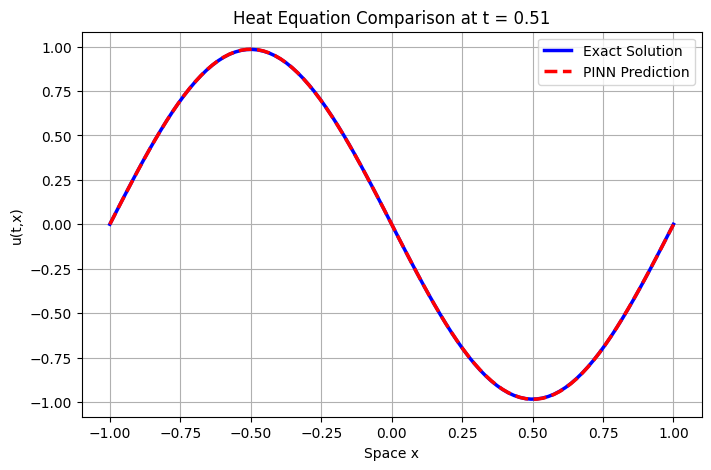

In [3]:
import torch
import torch.nn as nn
import numpy as np
import matplotlib.pyplot as plt

# Reproducibility ke liye seed set karein
torch.manual_seed(1234)
np.random.seed(1234)

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Using device: {device}")

class DNN(nn.Module):
    def __init__(self, layers):
        super(DNN, self).__init__()
        hidden_layers = []
        for i in range(len(layers) - 2):
            hidden_layers.append(nn.Linear(layers[i], layers[i+1]))
            hidden_layers.append(nn.Tanh())
        hidden_layers.append(nn.Linear(layers[-2], layers[-1]))
        self.net = nn.Sequential(*hidden_layers)

    def forward(self, t, x):
        inputs = torch.cat([t, x], dim=1)
        return self.net(inputs)

class HeatEquationPINN:
    def __init__(self, X_u, u_train, X_f, layers, nu=0.01/np.pi):
        self.t_u = X_u[:, 0:1].clone().detach().requires_grad_(True).to(device)
        self.x_u = X_u[:, 1:2].clone().detach().requires_grad_(True).to(device)
        self.u_train = u_train.to(device)

        self.t_f = X_f[:, 0:1].clone().detach().requires_grad_(True).to(device)
        self.x_f = X_f[:, 1:2].clone().detach().requires_grad_(True).to(device)

        self.nu = nu
        self.dnn = DNN(layers).to(device)

        self.optimizer = torch.optim.Adam(self.dnn.parameters(), lr=1e-3)
        self.optimizer_LBFGS = torch.optim.LBFGS(
            self.dnn.parameters(),
            lr=1.0,
            max_iter=1000,
            max_eval=1000,
            history_size=50,
            line_search_fn='strong_wolfe'
        )

    def net_u(self, t, x):
        return self.dnn(t, x)

    def net_f(self, t, x):
        u = self.net_u(t, x)
        u_t = torch.autograd.grad(u, t, grad_outputs=torch.ones_like(u), create_graph=True)[0]
        u_x = torch.autograd.grad(u, x, grad_outputs=torch.ones_like(u), create_graph=True)[0]
        u_xx = torch.autograd.grad(u_x, x, grad_outputs=torch.ones_like(u_x), create_graph=True)[0]

        # Heat Equation Residual: f = u_t - nu * u_xx = 0
        f = u_t - self.nu * u_xx
        return f

    def loss_fn(self):
        u_pred = self.net_u(self.t_u, self.x_u)
        loss_u = torch.mean((u_pred - self.u_train)**2)

        f_pred = self.net_f(self.t_f, self.x_f)
        loss_f = torch.mean(f_pred**2)

        return loss_u + loss_f

    def train(self, epochs):
        self.dnn.train()
        print("Training with Adam...")
        for epoch in range(epochs):
            self.optimizer.zero_grad()
            loss = self.loss_fn()
            loss.backward()
            self.optimizer.step()

            # Har 200 epochs par loss print hoga
            if epoch % 200 == 0:
                print(f"Epoch {epoch:4d} | Loss: {loss.item():.5e}")

        print("\nTraining with L-BFGS...")
        iter_count = [0]
        def closure():
            self.optimizer_LBFGS.zero_grad()
            loss = self.loss_fn()
            loss.backward()
            iter_count[0] += 1
            if iter_count[0] % 200 == 0 or iter_count[0] == 1:
                print(f"L-BFGS Iteration {iter_count[0]:4d} | Loss: {loss.item():.5e}")
            return loss
        self.optimizer_LBFGS.step(closure)

    def predict(self, X_star):
        self.dnn.eval()
        t = torch.tensor(X_star[:, 0:1], dtype=torch.float32, device=device)
        x = torch.tensor(X_star[:, 1:2], dtype=torch.float32, device=device)
        u = self.net_u(t, x)
        return u.detach().cpu().numpy()

# ==========================================
# Execution, Numerical Solutions & Error Calculation
# ==========================================
if __name__ == "__main__":
    layers = [2, 50, 50, 50, 1]

    # Initial Data Setup
    N0 = 100
    x0 = np.linspace(-1, 1, N0)[:, None]
    t0 = np.zeros_like(x0)
    u0 = -np.sin(np.pi * x0)

    X_u_train = np.hstack((t0, x0))
    u_train = u0

    # Collocation Points
    N_f = 10000
    t_f = np.random.uniform(0.0, 1.0, (N_f, 1))
    x_f = np.random.uniform(-1.0, 1.0, (N_f, 1))
    X_f_train = np.hstack((t_f, x_f))

    X_u_tensor = torch.tensor(X_u_train, dtype=torch.float32)
    u_tensor = torch.tensor(u_train, dtype=torch.float32)
    X_f_tensor = torch.tensor(X_f_train, dtype=torch.float32)

    # Model Training
    pinn = HeatEquationPINN(X_u_tensor, u_tensor, X_f_tensor, layers)
    pinn.train(epochs=1000)

    # Grid generation for testing and plotting
    n_t, n_x = 100, 100
    t_star = np.linspace(0, 1.0, n_t)
    x_star = np.linspace(-1.0, 1.0, n_x)
    T, X = np.meshgrid(t_star, x_star)
    X_star = np.hstack((T.flatten()[:, None], X.flatten()[:, None]))

    # Numerical Predictions
    U_pred = pinn.predict(X_star).reshape(n_x, n_t)

    # Analytical / Exact Solution for comparison: u(t,x) = -sin(pi*x) * exp(-nu * pi^2 * t)
    nu = 0.01 / np.pi
    U_exact = -np.sin(np.pi * X) * np.exp(-nu * (np.pi**2) * T)

    # Relative L2 Error Calculation
    error_l2 = np.linalg.norm(U_exact - U_pred) / np.linalg.norm(U_exact)
    print(f"\nRelative L2 Error between Exact and Predicted Solution: {error_l2:.5e}")

    # Print sample numerical values (Comparison at t = 0.5)
    t_idx = 50 # middle time index (~0.5)
    print("\n--- Numerical Values Comparison at t = 0.5 (Sample points) ---")
    print(f"{'x':<10} | {'Exact u(t,x)':<15} | {'Predicted u(t,x)':<15}")
    print("-" * 46)
    for idx in range(0, n_x, 20):
        print(f"{x_star[idx]:<10.2f} | {U_exact[idx, t_idx]:<15.5f} | {U_pred[idx, t_idx]:<15.5f}")

    # Plotting Graph (Exact vs Prediction at time snapshot t = 0.5)
    plt.figure(figsize=(8, 5))
    plt.plot(x_star, U_exact[:, t_idx], 'b-', linewidth=2.5, label='Exact Solution')
    plt.plot(x_star, U_pred[:, t_idx], 'r--', linewidth=2.5, label='PINN Prediction')
    plt.title(f'Heat Equation Comparison at t = {t_star[t_idx]:.2f}')
    plt.xlabel('Space x')
    plt.ylabel('u(t,x)')
    plt.legend()
    plt.grid(True)
    plt.show()

Using device: cuda
--- Training with Adam Optimizer ---
Adam Epoch    0 | Loss: 4.73034e-01
Adam Epoch  100 | Loss: 1.33199e-01
Adam Epoch  200 | Loss: 9.95903e-03
Adam Epoch  300 | Loss: 5.52416e-04
Adam Epoch  400 | Loss: 1.81291e-04
Adam Epoch  499 | Loss: 7.31974e-05

--- Training with L-BFGS Optimizer ---
L-BFGS Iteration   1 | Loss: 7.23714e-05
L-BFGS Iteration   2 | Loss: 7.51113e-03
L-BFGS Iteration   3 | Loss: 6.44968e-05
L-BFGS Iteration   4 | Loss: 6.44572e-05
L-BFGS Iteration   5 | Loss: 6.43788e-05
L-BFGS Iteration   6 | Loss: 6.42556e-05
L-BFGS Iteration   7 | Loss: 6.40217e-05
L-BFGS Iteration   8 | Loss: 6.34185e-05
L-BFGS Iteration   9 | Loss: 6.17706e-05
L-BFGS Iteration  10 | Loss: 5.85174e-05
L-BFGS Iteration  11 | Loss: 5.18661e-05
L-BFGS Iteration  12 | Loss: 4.20578e-05
L-BFGS Iteration  13 | Loss: 3.48065e-05
L-BFGS Iteration  14 | Loss: 3.29192e-05
L-BFGS Iteration  15 | Loss: 3.21982e-05
L-BFGS Iteration  16 | Loss: 3.04946e-05
L-BFGS Iteration  17 | Loss: 2.6

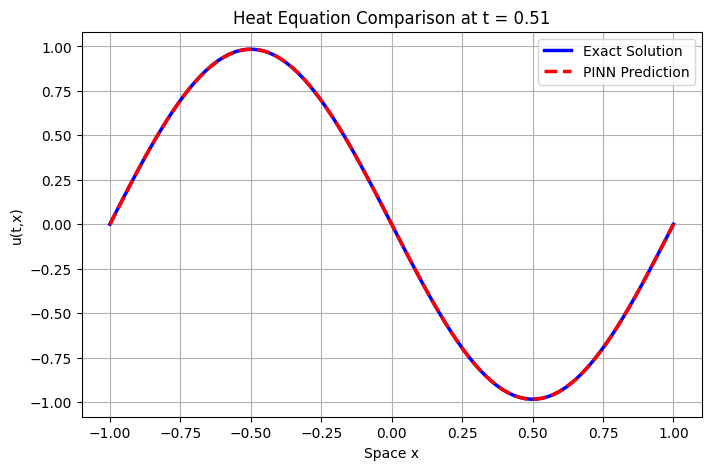

In [5]:
import torch
import torch.nn as nn
import numpy as np
import matplotlib.pyplot as plt

# Reproducibility ke liye seed set karein
torch.manual_seed(1234)
np.random.seed(1234)

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Using device: {device}")

class DNN(nn.Module):
    def __init__(self, layers):
        super(DNN, self).__init__()
        hidden_layers = []
        for i in range(len(layers) - 2):
            hidden_layers.append(nn.Linear(layers[i], layers[i+1]))
            hidden_layers.append(nn.Tanh())
        hidden_layers.append(nn.Linear(layers[-2], layers[-1]))
        self.net = nn.Sequential(*hidden_layers)

    def forward(self, t, x):
        inputs = torch.cat([t, x], dim=1)
        return self.net(inputs)

class HeatEquationPINN:
    def __init__(self, X_u, u_train, X_f, layers, nu=0.01/np.pi):
        self.t_u = X_u[:, 0:1].clone().detach().requires_grad_(True).to(device)
        self.x_u = X_u[:, 1:2].clone().detach().requires_grad_(True).to(device)
        self.u_train = u_train.to(device)

        self.t_f = X_f[:, 0:1].clone().detach().requires_grad_(True).to(device)
        self.x_f = X_f[:, 1:2].clone().detach().requires_grad_(True).to(device)

        self.nu = nu
        self.dnn = DNN(layers).to(device)

        # Optimizers
        self.optimizer_Adam = torch.optim.Adam(self.dnn.parameters(), lr=1e-3)
        self.optimizer_LBFGS = torch.optim.LBFGS(
            self.dnn.parameters(),
            lr=1.0,
            max_iter=300,
            max_eval=300,
            history_size=50,
            line_search_fn='strong_wolfe'
        )

    def net_u(self, t, x):
        return self.dnn(t, x)

    def net_f(self, t, x):
        u = self.net_u(t, x)
        u_t = torch.autograd.grad(u, t, grad_outputs=torch.ones_like(u), create_graph=True)[0]
        u_x = torch.autograd.grad(u, x, grad_outputs=torch.ones_like(u), create_graph=True)[0]
        u_xx = torch.autograd.grad(u_x, x, grad_outputs=torch.ones_like(u_x), create_graph=True)[0]

        # Heat Equation Residual: f = u_t - nu * u_xx = 0
        f = u_t - self.nu * u_xx
        return f

    def loss_fn(self):
        u_pred = self.net_u(self.t_u, self.x_u)
        loss_u = torch.mean((u_pred - self.u_train)**2)

        f_pred = self.net_f(self.t_f, self.x_f)
        loss_f = torch.mean(f_pred**2)

        return loss_u + loss_f

    def train(self, epochs):
        self.dnn.train()
        print("--- Training with Adam Optimizer ---")
        for epoch in range(epochs):
            self.optimizer_Adam.zero_grad()
            loss = self.loss_fn()
            loss.backward()
            self.optimizer_Adam.step()

            # Har 100 epochs par loss print hoga
            if epoch % 100 == 0 or epoch == epochs - 1:
                print(f"Adam Epoch {epoch:4d} | Loss: {loss.item():.5e}")

        print("\n--- Training with L-BFGS Optimizer ---")
        iter_count = [0]
        def closure():
            self.optimizer_LBFGS.zero_grad()
            loss = self.loss_fn()
            loss.backward()
            iter_count[0] += 1
            print(f"L-BFGS Iteration {iter_count[0]:3d} | Loss: {loss.item():.5e}")
            return loss

        self.optimizer_LBFGS.step(closure)

    def predict(self, X_star):
        self.dnn.eval()
        t = torch.tensor(X_star[:, 0:1], dtype=torch.float32, device=device)
        x = torch.tensor(X_star[:, 1:2], dtype=torch.float32, device=device)
        u = self.net_u(t, x)
        return u.detach().cpu().numpy()

# ==========================================
# Execution, Numerical Values & Graph Plotting
# ==========================================
if __name__ == "__main__":
    layers = [2, 50, 50, 50, 1]

    # Initial Data Setup
    N0 = 100
    x0 = np.linspace(-1, 1, N0)[:, None]
    t0 = np.zeros_like(x0)
    u0 = -np.sin(np.pi * x0)

    X_u_train = np.hstack((t0, x0))
    u_train = u0

    # Collocation Points
    N_f = 5000
    t_f = np.random.uniform(0.0, 1.0, (N_f, 1))
    x_f = np.random.uniform(-1.0, 1.0, (N_f, 1))
    X_f_train = np.hstack((t_f, x_f))

    X_u_tensor = torch.tensor(X_u_train, dtype=torch.float32)
    u_tensor = torch.tensor(u_train, dtype=torch.float32)
    X_f_tensor = torch.tensor(X_f_train, dtype=torch.float32)

    # Model Training
    pinn = HeatEquationPINN(X_u_tensor, u_tensor, X_f_tensor, layers)
    pinn.train(epochs=500)

    # Grid generation for testing and plotting
    n_t, n_x = 100, 100
    t_star = np.linspace(0, 1.0, n_t)
    x_star = np.linspace(-1.0, 1.0, n_x)
    T, X = np.meshgrid(t_star, x_star)
    X_star = np.hstack((T.flatten()[:, None], X.flatten()[:, None]))

    # Numerical Predictions
    U_pred = pinn.predict(X_star).reshape(n_x, n_t)

    # Exact Solution for comparison
    nu = 0.01 / np.pi
    U_exact = -np.sin(np.pi * X) * np.exp(-nu * (np.pi**2) * T)

    # Relative L2 Error Calculation
    error_l2 = np.linalg.norm(U_exact - U_pred) / np.linalg.norm(U_exact)
    print(f"\nRelative L2 Error between Exact and Predicted Solution: {error_l2:.5e}")

    # Print sample numerical values comparison at t = 0.5
    t_idx = 50
    print("\n--- Numerical Values Comparison at t = 0.5 (Sample points) ---")
    print(f"{'x':<10} | {'Exact u(t,x)':<15} | {'Predicted u(t,x)':<15}")
    print("-" * 46)
    for idx in range(0, n_x, 20):
        print(f"{x_star[idx]:<10.2f} | {U_exact[idx, t_idx]:<15.5f} | {U_pred[idx, t_idx]:<15.5f}")

    # Plotting Graph
    plt.figure(figsize=(8, 5))
    plt.plot(x_star, U_exact[:, t_idx], 'b-', linewidth=2.5, label='Exact Solution')
    plt.plot(x_star, U_pred[:, t_idx], 'r--', linewidth=2.5, label='PINN Prediction')
    plt.title(f'Heat Equation Comparison at t = {t_star[t_idx]:.2f}')
    plt.xlabel('Space x')
    plt.ylabel('u(t,x)')
    plt.legend()
    plt.grid(True)
    plt.show()

Using device: cuda

--- Training with Adam Optimizer ---
Adam Epoch    0 | Loss: 4.73034e-01
Adam Epoch  100 | Loss: 1.33199e-01
Adam Epoch  200 | Loss: 9.95903e-03
Adam Epoch  300 | Loss: 5.52416e-04
Adam Epoch  400 | Loss: 1.81291e-04
Adam Epoch  499 | Loss: 7.31974e-05

--- Training with L-BFGS Optimizer ---
L-BFGS Iteration   1 | Loss: 7.23714e-05
L-BFGS Iteration   2 | Loss: 7.51113e-03
L-BFGS Iteration   3 | Loss: 6.44968e-05
L-BFGS Iteration   4 | Loss: 6.44572e-05
L-BFGS Iteration   5 | Loss: 6.43788e-05
L-BFGS Iteration   6 | Loss: 6.42556e-05
L-BFGS Iteration   7 | Loss: 6.40217e-05
L-BFGS Iteration   8 | Loss: 6.34185e-05
L-BFGS Iteration   9 | Loss: 6.17706e-05
L-BFGS Iteration  10 | Loss: 5.85174e-05
L-BFGS Iteration  11 | Loss: 5.18661e-05
L-BFGS Iteration  12 | Loss: 4.20578e-05
L-BFGS Iteration  13 | Loss: 3.48065e-05
L-BFGS Iteration  14 | Loss: 3.29192e-05
L-BFGS Iteration  15 | Loss: 3.21982e-05
L-BFGS Iteration  16 | Loss: 3.04946e-05
L-BFGS Iteration  17 | Loss: 2.

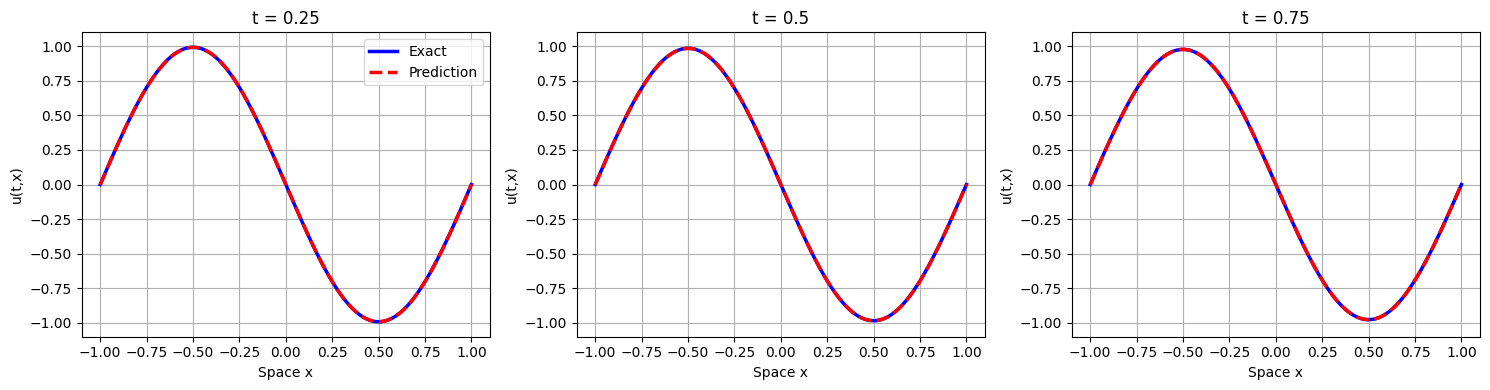

In [6]:
import torch
import torch.nn as nn
import numpy as np
import matplotlib.pyplot as plt

# Reproducibility ke liye seed set karein
torch.manual_seed(1234)
np.random.seed(1234)

# Device configuration (GPU ya CPU)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Using device: {device}")

class DNN(nn.Module):
    def __init__(self, layers):
        super(DNN, self).__init__()
        hidden_layers = []
        for i in range(len(layers) - 2):
            hidden_layers.append(nn.Linear(layers[i], layers[i+1]))
            hidden_layers.append(nn.Tanh())
        hidden_layers.append(nn.Linear(layers[-2], layers[-1]))
        self.net = nn.Sequential(*hidden_layers)

    def forward(self, t, x):
        inputs = torch.cat([t, x], dim=1)
        return self.net(inputs)

class HeatEquationPINN:
    def __init__(self, X_u, u_train, X_f, layers, nu=0.01/np.pi):
        self.t_u = X_u[:, 0:1].clone().detach().requires_grad_(True).to(device)
        self.x_u = X_u[:, 1:2].clone().detach().requires_grad_(True).to(device)
        self.u_train = u_train.to(device)

        self.t_f = X_f[:, 0:1].clone().detach().requires_grad_(True).to(device)
        self.x_f = X_f[:, 1:2].clone().detach().requires_grad_(True).to(device)

        self.nu = nu
        self.dnn = DNN(layers).to(device)

        # Optimizers setup
        self.optimizer_Adam = torch.optim.Adam(self.dnn.parameters(), lr=1e-3)
        self.optimizer_LBFGS = torch.optim.LBFGS(
            self.dnn.parameters(),
            lr=1.0,
            max_iter=500,
            max_eval=500,
            history_size=50,
            line_search_fn='strong_wolfe'
        )

    def net_u(self, t, x):
        return self.dnn(t, x)

    def net_f(self, t, x):
        u = self.net_u(t, x)
        u_t = torch.autograd.grad(u, t, grad_outputs=torch.ones_like(u), create_graph=True)[0]
        u_x = torch.autograd.grad(u, x, grad_outputs=torch.ones_like(u), create_graph=True)[0]
        u_xx = torch.autograd.grad(u_x, x, grad_outputs=torch.ones_like(u_x), create_graph=True)[0]

        # Heat Equation Residual: f = u_t - nu * u_xx = 0
        f = u_t - self.nu * u_xx
        return f

    def loss_fn(self):
        u_pred = self.net_u(self.t_u, self.x_u)
        loss_u = torch.mean((u_pred - self.u_train)**2)

        f_pred = self.net_f(self.t_f, self.x_f)
        loss_f = torch.mean(f_pred**2)

        return loss_u + loss_f

    def train(self, epochs):
        self.dnn.train()
        print("\n--- Training with Adam Optimizer ---")
        for epoch in range(epochs):
            self.optimizer_Adam.zero_grad()
            loss = self.loss_fn()
            loss.backward()
            self.optimizer_Adam.step()

            if epoch % 100 == 0 or epoch == epochs - 1:
                print(f"Adam Epoch {epoch:4d} | Loss: {loss.item():.5e}")

        print("\n--- Training with L-BFGS Optimizer ---")
        iter_count = [0]
        def closure():
            self.optimizer_LBFGS.zero_grad()
            loss = self.loss_fn()
            loss.backward()
            iter_count[0] += 1
            print(f"L-BFGS Iteration {iter_count[0]:3d} | Loss: {loss.item():.5e}")
            return loss

        self.optimizer_LBFGS.step(closure)

    def predict(self, X_star):
        self.dnn.eval()
        t = torch.tensor(X_star[:, 0:1], dtype=torch.float32, device=device)
        x = torch.tensor(X_star[:, 1:2], dtype=torch.float32, device=device)
        u = self.net_u(t, x)
        return u.detach().cpu().numpy()

# ==========================================
# Execution & Multi-Snapshot Evaluation
# ==========================================
if __name__ == "__main__":
    layers = [2, 50, 50, 50, 1]

    # 1. Initial Data Setup (t = 0)
    N0 = 100
    x0 = np.linspace(-1, 1, N0)[:, None]
    t0 = np.zeros_like(x0)
    u0 = -np.sin(np.pi * x0)

    X_u_train = np.hstack((t0, x0))
    u_train = u0

    # 2. Collocation Points Setup
    N_f = 5000
    t_f = np.random.uniform(0.0, 1.0, (N_f, 1))
    x_f = np.random.uniform(-1.0, 1.0, (N_f, 1))
    X_f_train = np.hstack((t_f, x_f))

    X_u_tensor = torch.tensor(X_u_train, dtype=torch.float32)
    u_tensor = torch.tensor(u_train, dtype=torch.float32)
    X_f_tensor = torch.tensor(X_f_train, dtype=torch.float32)

    # 3. Model Initialize & Train
    pinn = HeatEquationPINN(X_u_tensor, u_tensor, X_f_tensor, layers)
    pinn.train(epochs=500)

    # 4. Grid Generation for Testing
    n_t, n_x = 100, 100
    t_star = np.linspace(0, 1.0, n_t)
    x_star = np.linspace(-1.0, 1.0, n_x)
    T, X = np.meshgrid(t_star, x_star)
    X_star = np.hstack((T.flatten()[:, None], X.flatten()[:, None]))

    U_pred = pinn.predict(X_star).reshape(n_x, n_t)

    # Analytical Exact Solution
    nu = 0.01 / np.pi
    U_exact = -np.sin(np.pi * X) * np.exp(-nu * (np.pi**2) * T)

    # Overall Relative L2 Error
    error_l2_total = np.linalg.norm(U_exact - U_pred) / np.linalg.norm(U_exact)
    print(f"\nOverall Relative L2 Error: {error_l2_total:.5e}")

    # ==========================================
    # Multi-Time Snapshots Comparison & Plotting
    # ==========================================
    snap_times = [0.25, 0.50, 0.75]
    fig, axes = plt.subplots(1, len(snap_times), figsize=(15, 4))

    for i, st in enumerate(snap_times):
        t_idx = np.argmin(np.abs(t_star - st))
        u_exact_snap = U_exact[:, t_idx]
        u_pred_snap = U_pred[:, t_idx]

        # Specific snapshot error
        err_t = np.linalg.norm(u_exact_snap - u_pred_snap) / np.linalg.norm(u_exact_snap)
        print(f"Relative L2 Error at t = {st}: {err_t:.5e}")

        # Plotting subplot
        ax = axes[i]
        ax.plot(x_star, u_exact_snap, 'b-', linewidth=2.5, label='Exact')
        ax.plot(x_star, u_pred_snap, 'r--', linewidth=2.5, label='Prediction')
        ax.set_title(f't = {st}')
        ax.set_xlabel('Space x')
        ax.set_ylabel('u(t,x)')
        ax.grid(True)
        ax.set_ylim(-1.1, 1.1)
        if i == 0:
            ax.legend(loc='upper right')

    plt.tight_layout()
    plt.show()